# Customer Retention, Monetization, and Churn Risk Analysis in B2B SaaS

**Role / Focus:** Business Intelligence & Data Analytics  
**Data Source:** B2B SaaS Churn Dataset (`MP_Synthetics_50000_Rows.csv`, hosted in the `Final-Project` repository)  
**Dataset Size & Structure:** 50,000 records (customer accounts) and 18 columns  

### Data Overview
The dataset contains information about B2B subscription customers across several dimensions:
* **Company Profile & Segmentation:** `Customer_ID`, `Company_Name`, `Industry`, `Country`, `Company_Size`, `Account_Manager`
* **Plan & Revenue:** `Plan_Tier`, `Billing_Cycle`, `Monthly_Recurring_Revenue`, `Payment_Status`
* **Activity & Product Usage:** `Signup_Date`, `Last_Active_Date`, `Active_Seats_Used`, `Total_Seats_Allowed`, `Support_Tickets_30d`, `Feature_Adoption_Rate`
* **Risk & Churn:** `Churn_Risk_Score`, `Is_Churned`

### Project Objective
Analyze Monthly Recurring Revenue (MRR) distribution, seat utilization, customer activity, and key drivers of churn (`Is_Churned`) to deliver actionable business recommendations for customer retention and revenue growth.

## 1. Importing Libraries and Loading the Dataset
We import the required Python libraries for data analysis and load the raw dataset from the public GitHub repository into a `pandas` DataFrame.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')

url = (
    'https://raw.githubusercontent.com/olhabohatska/'
    'Final-Project/main/MP_Synthetics_50000_Rows.csv'
)
df = pd.read_csv(url)

print(df.shape)
df.head()

(50000, 18)


,Customer_ID,Company_Name,Industry,Country,Company_Size,Account_Manager,Plan_Tier,Billing_Cycle,Monthly_Recurring_Revenue,Signup_Date,Last_Active_Date,Payment_Status,Active_Seats_Used,Total_Seats_Allowed,Support_Tickets_30d,Feature_Adoption_Rate,Churn_Risk_Score,Is_Churned
0,CUST-1001,Pulse Net 944,HealthTech,Australia,11-50,Sarah Jenkins,Starter,Annual,49,2025-03-12,2026-02-18,Active,3,8,5,44%,Low,0
1,CUST-1002,Pulse Logic 332,CyberSecurity,USA,51-200,David Ross,Pro,Annual,499,2023-09-29,2026-02-25,Active,13,24,3,58%,Low,0
2,CUST-1003,Secure Flow 975,DevTools,India,1-10,David Ross,Starter,Monthly,79,2025-03-16,2026-02-19,Active,6,8,5,70%,Low,0
3,CUST-1004,Quantum Scale 657,EdTech,Singapore,51-200,Marcus Vance,Pro,Annual,249,2024-03-05,2026-02-22,Active,34,39,2,90%,Low,0
4,CUST-1005,Quantum Sphere 308,E-Commerce,Germany,1-10,Aisha Khan,Starter,Monthly,129,2025-02-28,2026-02-22,Active,8,9,3,93%,Low,0


## 2. Initial Data Exploration and Data Quality Check
At this stage, we inspect the dataset shape, check for duplicate rows and missing values, and review column data types (`dtypes`) prior to data cleaning and metric calculation.

In [2]:
print('Розмір таблиці:', df.shape)
print('\nДублікатів:', df.duplicated().sum())
print('\nПропуски по колонках:\n', df.isna().sum())
print('\nКолонки та типи:\n', df.dtypes)

Розмір таблиці: (50000, 18)

Дублікатів: 0

Пропуски по колонках:
 Customer_ID                  0
Company_Name                 0
Industry                     0
Country                      0
Company_Size                 0
Account_Manager              0
Plan_Tier                    0
Billing_Cycle                0
Monthly_Recurring_Revenue    0
Signup_Date                  0
Last_Active_Date             0
Payment_Status               0
Active_Seats_Used            0
Total_Seats_Allowed          0
Support_Tickets_30d          0
Feature_Adoption_Rate        0
Churn_Risk_Score             0
Is_Churned                   0
dtype: int64

Колонки та типи:
 Customer_ID                  object
Company_Name                 object
Industry                     object
Country                      object
Company_Size                 object
Account_Manager              object
Plan_Tier                    object
Billing_Cycle                object
Monthly_Recurring_Revenue     int64
Signup_Date        

**Key Observations from the Data Audit:**
* The table contains **50,000 rows and 18 columns**, with **0 duplicate rows** and **0 missing values** (`NaN`) across all columns.
* `Signup_Date` and `Last_Active_Date` are currently stored as `object` and should be converted to `datetime` for time-based analysis.
* `Feature_Adoption_Rate` and `Churn_Risk_Score` also have the `object` data type, so we should inspect their values (e.g., percentage strings or category labels) and convert them to numeric or ordered categorical types where needed
.

## 3. Data Cleaning and Feature Engineering
Before answering business questions, we inspect the exact values of `Feature_Adoption_Rate` and `Churn_Risk_Score`, convert date columns (`Signup_Date`, `Last_Active_Date`) to `datetime`, and engineer key B2B SaaS / BI metrics such as **seat utilization** (`Seat_Utilization`), **customer tenure** (`Tenure_Days`), and **days since last activity** (`Days_Since_Active`).

In [3]:
# Inspect values in columns that currently have the object dtype
print(
    'Feature_Adoption_Rate sample:',
    df['Feature_Adoption_Rate'].head(10).tolist(),
)
print('Churn_Risk_Score unique:', df['Churn_Risk_Score'].unique()[:15])
print('Is_Churned unique:', df['Is_Churned'].unique())
print('Payment_Status unique:', df['Payment_Status'].unique())

df_clean = df.copy()

# Convert date columns to datetime
df_clean['Signup_Date'] = pd.to_datetime(df_clean['Signup_Date'])
df_clean['Last_Active_Date'] = pd.to_datetime(df_clean['Last_Active_Date'])

# Clean Feature_Adoption_Rate (handles both plain numbers and 'XX%' strings)
if df_clean['Feature_Adoption_Rate'].dtype == 'object':
    cleaned_adoption = (
        df_clean['Feature_Adoption_Rate']
        .astype(str)
        .str.replace('%', '', regex=False)
        .str.strip()
    )
    df_clean['Feature_Adoption_Rate_Num'] = pd.to_numeric(
        cleaned_adoption, errors='coerce'
    )
else:
    df_clean['Feature_Adoption_Rate_Num'] = df_clean['Feature_Adoption_Rate']

# Convert Churn_Risk_Score to numeric where possible
df_clean['Churn_Risk_Score_Num'] = pd.to_numeric(
    df_clean['Churn_Risk_Score'], errors='coerce'
)

# Engineer key BI metrics
df_clean['Seat_Utilization'] = np.where(
    df_clean['Total_Seats_Allowed'] > 0,
    df_clean['Active_Seats_Used'] / df_clean['Total_Seats_Allowed'],
    0.0,
)

snapshot_date = df_clean['Last_Active_Date'].max()
df_clean['Tenure_Days'] = (
    df_clean['Last_Active_Date'] - df_clean['Signup_Date']
).dt.days
df_clean['Days_Since_Active'] = (
    snapshot_date - df_clean['Last_Active_Date']
).dt.days
df_clean['Churned_MRR'] = np.where(
    df_clean['Is_Churned'] == 1, df_clean['Monthly_Recurring_Revenue'], 0
)

print('\nUpdated dtypes for engineered and date columns:')
print(
    df_clean[[
        'Signup_Date',
        'Last_Active_Date',
        'Feature_Adoption_Rate_Num',
        'Churn_Risk_Score_Num',
        'Seat_Utilization',
        'Tenure_Days',
        'Days_Since_Active',
        'Churned_MRR',
    ]].dtypes
)

Feature_Adoption_Rate sample: ['44%', '58%', '70%', '90%', '93%', '60%', '49%', '65%', '59%', '63%']
Churn_Risk_Score unique: ['Low' 'Medium' 'High']
Is_Churned unique: [0 1]
Payment_Status unique: ['Active' 'Pending' 'Failed']

Updated dtypes for engineered and date columns:
Signup_Date                  datetime64[ns]
Last_Active_Date             datetime64[ns]
Feature_Adoption_Rate_Num             int64
Churn_Risk_Score_Num                float64
Seat_Utilization                    float64
Tenure_Days                           int64
Days_Since_Active                     int64
Churned_MRR                           int64
dtype: object


In [4]:
risk_mapping = {'Low': 1, 'Medium': 2, 'High': 3}
df_clean['Churn_Risk_Level'] = pd.Categorical(
    df_clean['Churn_Risk_Score'],
    categories=['Low', 'Medium', 'High'],
    ordered=True,
)
df_clean['Churn_Risk_Score_Num'] = df_clean['Churn_Risk_Score'].map(risk_mapping)

print('Nulls in Churn_Risk_Score_Num:', df_clean['Churn_Risk_Score_Num'].isna().sum())

Nulls in Churn_Risk_Score_Num: 0


**Cleaning & Feature Engineering Summary:**
* Converted `Signup_Date` and `Last_Active_Date` to `datetime64[ns]`.
* Stripped `%` symbols from `Feature_Adoption_Rate` to create numeric `Feature_Adoption_Rate_Num` (`int64`).
* Mapped `Churn_Risk_Score` (`Low`, `Medium`, `High`) into an ordered category (`Churn_Risk_Level`) and numeric scale (`Churn_Risk_Score_Num`: `1` to `3`).
* Engineered business metrics: `Seat_Utilization`, `Tenure_Days`, `Days_Since_Active`, and `Churned_MRR`.

## 4. Business Questions and Analysis
We answer 10 targeted business questions covering revenue structure, segmentation, product adoption, payment health, account management, growth dynamics, and churn risk.

### Q1–Q3: Revenue Structure, Top Markets & Industries, and Company Size
**Q1 (MRR & Billing Cycle):** What are total, mean, and median MRR, and how do MRR and churn rate (`Is_Churned`) differ between `Monthly` and `Annual` billing cycles and across `Plan_Tier`?

**Q2 (Geography & Industry):** Which top 5 countries and industries generate the highest total MRR, and does customer count match revenue leadership?

**Q3 (Company Size):** How do MRR, allowed seats, and churn rate vary across `Company_Size` segments?

In [5]:
# Q1: MRR and churn by Billing_Cycle and Plan_Tier
q1_summary = (
    df_clean.groupby(['Billing_Cycle', 'Plan_Tier'], observed=False)
    .agg(
        customers=('Customer_ID', 'count'),
        total_mrr=('Monthly_Recurring_Revenue', 'sum'),
        mean_mrr=('Monthly_Recurring_Revenue', 'mean'),
        median_mrr=('Monthly_Recurring_Revenue', 'median'),
        churn_rate=('Is_Churned', 'mean'),
    )
    .assign(churn_rate_pct=lambda x: (x['churn_rate'] * 100).round(2))
    .drop(columns=['churn_rate'])
)
print('--- Q1: MRR & Churn by Billing Cycle and Plan Tier ---')
display(q1_summary)

--- Q1: MRR & Churn by Billing Cycle and Plan Tier ---


customers  total_mrr     mean_mrr  median_mrr  \
Billing_Cycle Plan_Tier                                                   
Annual        Enterprise       1768    8823193  4990.493778      4993.0   
              Pro              5142    1857108   361.164527       399.0   
              Starter         10557     936493    88.708250        79.0   
Monthly       Enterprise       3283   16387874  4991.737435      4988.0   
              Pro              9799    3533051   360.552199       299.0   
              Starter         19451    1730189    88.951159        79.0   

                          churn_rate_pct  
Billing_Cycle Plan_Tier                   
Annual        Enterprise            1.36  
              Pro                   1.28  
              Starter               2.24  
Monthly       Enterprise            1.01  
              Pro                   1.10  
              Starter               2.30

In [6]:
# Q2: Top 5 Countries and Top 5 Industries by Total MRR
top_countries = (
    df_clean.groupby('Country', observed=False)
    .agg(
        customers=('Customer_ID', 'count'),
        total_mrr=('Monthly_Recurring_Revenue', 'sum'),
        mean_mrr=('Monthly_Recurring_Revenue', 'mean'),
    )
    .sort_values('total_mrr', ascending=False)
    .head(5)
)
top_industries = (
    df_clean.groupby('Industry', observed=False)
    .agg(
        customers=('Customer_ID', 'count'),
        total_mrr=('Monthly_Recurring_Revenue', 'sum'),
        churn_rate_pct=('Is_Churned', lambda s: round(s.mean() * 100, 2)),
    )
    .sort_values('total_mrr', ascending=False)
    .head(5)
)
print('\n--- Q2a: Top 5 Countries by Total MRR ---')
display(top_countries)
print('\n--- Q2b: Top 5 Industries by Total MRR ---')
display(top_industries)



--- Q2a: Top 5 Countries by Total MRR ---


,customers,total_mrr,mean_mrr
Country,,,
USA,6245,4340796,695.083427
Singapore,6312,4291233,679.853137
UK,6178,4262820,690.000000
India,6394,4227366,661.145762
Germany,6328,4197075,663.254583



--- Q2b: Top 5 Industries by Total MRR ---


,customers,total_mrr,churn_rate_pct
Industry,,,
CyberSecurity,6375,4346064,1.76
Logistics,6266,4287508,1.90
EdTech,6259,4265324,2.05
FinTech,6183,4222265,1.78
HealthTech,6264,4152494,1.77


In [7]:
# Q3: Metrics by Company_Size
q3_company_size = (
    df_clean.groupby('Company_Size', observed=False)
    .agg(
        customers=('Customer_ID', 'count'),
        total_mrr=('Monthly_Recurring_Revenue', 'sum'),
        mean_mrr=('Monthly_Recurring_Revenue', 'mean'),
        avg_seats_allowed=('Total_Seats_Allowed', 'mean'),
        churn_rate_pct=('Is_Churned', lambda s: round(s.mean() * 100, 2)),
    )
    .sort_values('total_mrr', ascending=False)
)
print('\n--- Q3: Metrics by Company Size ---')
display(q3_company_size)


--- Q3: Metrics by Company Size ---


,customers,total_mrr,mean_mrr,avg_seats_allowed,churn_rate_pct
Company_Size,,,,,
201-500,5508,10027334,1820.503631,207.081518,1.13
1000+,1667,8392576,5034.538692,572.797241,1.20
501-1000,1647,8155336,4951.630844,576.874924,0.97
51-200,11170,4025980,360.427932,39.611817,1.19
1-10,21089,1875191,88.917967,6.509934,2.27
11-50,8919,791491,88.742124,6.491199,2.31


**Observations (Q1–Q3):**
* **Plan & Billing Cycle (Q1):** `Enterprise` generates the highest total MRR (approx. 16.39M on `Monthly` and approx. 8.82M on `Annual`) with the smallest customer count, while `Starter` has the largest user base (19,451 `Monthly` and 10,557 `Annual` accounts) and the highest churn rate (2.30% and 2.24% vs. approx. 1.01%–1.36% in `Pro` and `Enterprise`).
* **Geography & Industry (Q2):** Top 5 countries by total MRR are led by the `USA` (approx. 4.34M), followed closely by `Singapore`, `UK`, `India`, and `Germany` (4.20M to 4.29M each). Top 5 industries by total MRR are led by `CyberSecurity` (approx. 4.35M), followed by `Logistics`, `EdTech`, `FinTech`, and `HealthTech`. Customer volumes across top segments are similar, so differences in average revenue per account slightly shift revenue rankings vs. customer counts.
* **Company Size (Q3):** The `201-500` segment leads in total MRR (approx. 10.03M), while `1000+` (5,035 mean MRR, approx. 573 average allowed seats) and `501-1000` (4,952 mean MRR, approx. 577 average allowed seats) have the highest per-account scale. Churn is lowest in `501-1000` (0.97%) and highest in `11-50` (2.31%) and `1-10` (2.27%).

**Business Recommendations (Q1–Q3):**
* **Reduce Churn on `Starter` & Small Segments (`1-10`, `11-50`):** Because `Starter` accounts and smaller companies have the highest churn rates (~2.24%–2.31%) despite large customer counts, introduce automated onboarding checklists, in-app guidance, and early-warning health triggers during the first weeks after signup.
* **Protect & Expand High-MRR Segments (`Enterprise`, `201-500`, `501-1000`, `1000+`):** Since `Enterprise` and mid-to-large companies generate the bulk of total and average MRR with much lower churn (~0.97%–1.36%), prioritize proactive customer success check-ins, dedicated account coverage, and seat/plan expansion motions in these cohorts.
* **Align Go-to-Market Focus with Revenue & Margin:** Maintain strong localization and sales/marketing focus in top revenue markets (`USA`, `Singapore`, `UK`, `India`, `Germany`) and high-value verticals (`CyberSecurity`, `Logistics`, `EdTech`, `FinTech`, `HealthTech`), while comparing segment retention and acquisition cost before scaling spend.

### Q4–Q7: Seat Utilization, Recency & Churn, Account Managers, and Signup Trends
**Q4 (Seat Utilization):** What is the average `Seat_Utilization` across `Plan_Tier`, and what share of customers use under 50% of allowed seats (underutilization / renewal risk) vs. 90%+ (expansion opportunity)?

**Q5 (Inactivity & Churn):** How does `Days_Since_Active` and `Payment_Status` (`Active`, `Pending`, `Failed`) relate to churn (`Is_Churned`) and churned MRR (`Churned_MRR`)?

**Q6 (Account Managers):** How are customers, total MRR, and churn rates distributed across `Account_Manager`?

**Q7 (Signup Trends):** How did monthly new customer signups and new MRR (`Signup_Date` monthly cohort) evolve over time?

In [8]:
# Q4: Seat utilization by Plan_Tier and under/over-utilization shares
df_clean['Underutilized_50pct'] = df_clean['Seat_Utilization'] < 0.50
df_clean['High_Util_90pct'] = df_clean['Seat_Utilization'] >= 0.90

q4_seats = (
    df_clean.groupby('Plan_Tier', observed=False)
    .agg(
        customers=('Customer_ID', 'count'),
        mean_seat_util_pct=('Seat_Utilization', lambda s: round(s.mean() * 100, 2)),
        under_50_pct_share=('Underutilized_50pct', lambda s: round(s.mean() * 100, 2)),
        high_90_pct_share=('High_Util_90pct', lambda s: round(s.mean() * 100, 2)),
    )
)
print('--- Q4: Seat Utilization by Plan Tier ---')
display(q4_seats)

--- Q4: Seat Utilization by Plan Tier ---


,customers,mean_seat_util_pct,under_50_pct_share,high_90_pct_share
Plan_Tier,,,,
Enterprise,5051,69.68,17.09,16.81
Pro,14941,68.54,18.34,15.03
Starter,30008,60.56,24.94,2.17


In [9]:
# Q5: Churn and Churned MRR by Payment_Status and activity recency buckets
df_clean['Activity_Bucket'] = pd.cut(
    df_clean['Days_Since_Active'],
    bins=[-1, 7, 30, 90, 99999],
    labels=['0-7 days', '8-30 days', '31-90 days', '90+ days'],
)
q5_payment = (
    df_clean.groupby('Payment_Status', observed=False)
    .agg(
        customers=('Customer_ID', 'count'),
        churn_rate_pct=('Is_Churned', lambda s: round(s.mean() * 100, 2)),
        churned_mrr=('Churned_MRR', 'sum'),
    )
)
q5_activity = (
    df_clean.groupby('Activity_Bucket', observed=False)
    .agg(
        customers=('Customer_ID', 'count'),
        churn_rate_pct=('Is_Churned', lambda s: round(s.mean() * 100, 2)),
        churned_mrr=('Churned_MRR', 'sum'),
    )
)
print('\n--- Q5a: Churn by Payment Status ---')
display(q5_payment)
print('\n--- Q5b: Churn by Days Since Active ---')
display(q5_activity)



--- Q5a: Churn by Payment Status ---


,customers,churn_rate_pct,churned_mrr
Payment_Status,,,
Active,44965,1.14,203895
Failed,2029,14.49,151870
Pending,3006,3.63,40275



--- Q5b: Churn by Days Since Active ---


,customers,churn_rate_pct,churned_mrr
Activity_Bucket,,,
0-7 days,28253,0.00,0
8-30 days,20840,0.04,1421
31-90 days,388,100.00,162284
90+ days,519,100.00,232335


In [10]:
# Q6: Account Manager workload, MRR, and churn
q6_am = (
    df_clean.groupby('Account_Manager', observed=False)
    .agg(
        customers=('Customer_ID', 'count'),
        total_mrr=('Monthly_Recurring_Revenue', 'sum'),
        churn_rate_pct=('Is_Churned', lambda s: round(s.mean() * 100, 2)),
    )
    .sort_values('total_mrr', ascending=False)
)
print('\n--- Q6: Account Manager Performance ---')
display(q6_am)


--- Q6: Account Manager Performance ---


,customers,total_mrr,churn_rate_pct
Account_Manager,,,
David Ross,10124,6899951,1.76
Sarah Jenkins,9970,6779589,1.96
Marcus Vance,9983,6664859,1.95
Elena Rostova,9987,6593989,1.86
Aisha Khan,9936,6329520,1.63


In [11]:
# Q7: Monthly signup trend (customers and MRR)
df_clean['Signup_Month'] = df_clean['Signup_Date'].dt.to_period('M').astype(str)
q7_monthly = (
    df_clean.groupby('Signup_Month', observed=False)
    .agg(
        new_customers=('Customer_ID', 'count'),
        signup_mrr=('Monthly_Recurring_Revenue', 'sum'),
    )
    .reset_index()
)
print('\n--- Q7: Monthly Signup Trend (First 12 Months) ---')
display(q7_monthly.head(12))


--- Q7: Monthly Signup Trend (First 12 Months) ---


,Signup_Month,new_customers,signup_mrr
0,2022-11,569,334625
1,2022-12,1285,855765
2,2023-01,1333,821613
3,2023-02,1203,759778
4,2023-03,1289,866148
5,2023-04,1287,906749
6,2023-05,1305,832000
7,2023-06,1234,815717
8,2023-07,1299,887603
9,2023-08,1292,907373


**Observations (Q4–Q7):**
* **Seat Utilization (Q4):** Average seat utilization is highest in `Enterprise` (69.68%) and `Pro` (68.54%), and lowest in `Starter` (60.56%). In `Starter`, 24.94% of accounts use under 50% of allowed seats and only 2.17% reach 90%+, whereas `Enterprise` and `Pro` have much higher shares of 90%+ seat utilization (16.81% and 15.03%).
* **Payment Status & Inactivity (Q5):** Customers with `Failed` payments have a 14.49% churn rate (151,870 churned MRR) compared to 3.63% for `Pending` (40,275 churned MRR) and 1.14% for `Active`. By activity recency, churn is near zero within 0–30 days (`0-7 days`: 0.00%, `8-30 days`: 0.04%), while accounts inactive for `31-90 days` and `90+ days` show 100.00% churn (162,284 and 232,335 churned MRR).
* **Account Managers (Q6):** Customer count (9,936 to 10,124), total MRR (6.33M to 6.90M), and churn rates (1.63% to 1.96%) are evenly distributed across all five account managers (`David Ross`, `Sarah Jenkins`, `Marcus Vance`, `Elena Rostova`, `Aisha Khan`).
* **Signup Trends (Q7):** After a partial initial month in `2022-11` (569 customers, 334,625 MRR), monthly acquisitions from `2022-12` through `2023-10` remain steady at roughly 1,203 to 1,352 new customers and 760k to 909k in monthly signup MRR.

**Business Recommendations (Q4–Q7):**
* **Act Early on Inactivity & Payment Failures:** Trigger automated re-engagement nudges before accounts cross the 30-day inactivity mark, and set up immediate dunning/retry flows for `Failed` and `Pending` payments to recover high-value MRR before churn occurs.
* **Right-Size `Starter` & Expand High-Utilization Accounts:** Help underutilized `Starter` accounts (<50% seats) adopt key features or downsize seats to prevent renewal drop-off, while targeting `Enterprise` and `Pro` accounts at 90%+ utilization for seat expansion offers.
* **Keep Balanced Account Coverage & Monitor Full Signup Timeline:** Maintain the balanced workload across account managers while reviewing retention rates across individual account managers and across the full multi-year `Signup_Month` series.

### Q8–Q10: Customer Tenure, Risk Scoring & Support Load, and Overall Revenue at Risk
**Q8 (Customer Tenure & Engagement):** How do average MRR, `Seat_Utilization`, and `Feature_Adoption_Rate_Num` change across customer tenure buckets (`Tenure_Days`: `0-90d`, `91-180d`, `181-365d`, `365d+`)?

**Q9 (Churn Risk & Support Load):** How strongly do `Churn_Risk_Level` (`Low`, `Medium`, `High`), 30-day support ticket volume (`Support_Tickets_30d`), and feature adoption align with actual churn (`Is_Churned`)?

**Q10 (Portfolio Revenue at Risk):** What are the overall churn rate, total MRR, and total churned MRR (`Churned_MRR`), and what percentage of total portfolio MRR is lost to churn?

In [12]:
# Q8: Tenure buckets vs. MRR, Seat Utilization, and Feature Adoption
df_clean['Tenure_Bucket'] = pd.cut(
    df_clean['Tenure_Days'],
    bins=[-1, 90, 180, 365, 99999],
    labels=['0-90d', '91-180d', '181-365d', '365d+'],
)
q8_tenure = (
    df_clean.groupby('Tenure_Bucket', observed=False)
    .agg(
        customers=('Customer_ID', 'count'),
        mean_mrr=('Monthly_Recurring_Revenue', 'mean'),
        mean_seat_util_pct=('Seat_Utilization', lambda s: round(s.mean() * 100, 2)),
        mean_feature_adoption=('Feature_Adoption_Rate_Num', 'mean'),
    )
    .round(2)
)
print('--- Q8: Tenure Buckets vs. MRR & Product Engagement ---')
display(q8_tenure)

--- Q8: Tenure Buckets vs. MRR & Product Engagement ---


,customers,mean_mrr,mean_seat_util_pct,mean_feature_adoption
Tenure_Bucket,,,,
0-90d,2995,717.13,63.88,69.39
91-180d,3879,665.84,64.12,70.19
181-365d,7904,664.12,63.69,69.76
365d+,35163,661.70,63.90,69.81


In [13]:
# Q9: Churn rate and support tickets by Churn_Risk_Level
q9_risk = (
    df_clean.groupby('Churn_Risk_Level', observed=False)
    .agg(
        customers=('Customer_ID', 'count'),
        churn_rate_pct=('Is_Churned', lambda s: round(s.mean() * 100, 2)),
        avg_tickets_30d=('Support_Tickets_30d', 'mean'),
        avg_feature_adoption=('Feature_Adoption_Rate_Num', 'mean'),
    )
    .round(2)
)
print('\n--- Q9: Churn & Engagement by Churn Risk Level ---')
display(q9_risk)


--- Q9: Churn & Engagement by Churn Risk Level ---


,customers,churn_rate_pct,avg_tickets_30d,avg_feature_adoption
Churn_Risk_Level,,,,
Low,49529,1.49,3.33,70.01
Medium,454,37.00,5.36,46.54
High,17,64.71,6.82,37.59


In [14]:
# Q10: Overall MRR vs. Churned MRR and share of total MRR
total_mrr_all = df_clean['Monthly_Recurring_Revenue'].sum()
churned_mrr_all = df_clean['Churned_MRR'].sum()
churn_rate_all = df_clean['Is_Churned'].mean() * 100

q10_overview = pd.DataFrame({
    'Metric': [
        'Total Customers',
        'Overall Churn Rate (%)',
        'Total MRR',
        'Churned MRR',
        'Churned Share of Total MRR (%)',
    ],
    'Value': [
        f"{len(df_clean):,}",
        f"{churn_rate_all:.2f}%",
        f"{total_mrr_all:,}",
        f"{churned_mrr_all:,}",
        f"{(churned_mrr_all / total_mrr_all) * 100:.2f}%",
    ],
})
print('\n--- Q10: Portfolio Revenue & Churn Overview ---')
display(q10_overview)


--- Q10: Portfolio Revenue & Churn Overview ---


,Metric,Value
0,Total Customers,"50,000"
1,Overall Churn Rate (%),1.83%
2,Total MRR,"33,267,908"
3,Churned MRR,"396,040"
4,Churned Share of Total MRR (%),1.19%


**Observations (Q8–Q10):**
* **Tenure & Engagement (Q8):** Most accounts (35,163) fall into the `365d+` tenure bucket. Average seat utilization (63.69% to 64.12%), feature adoption (69.39 to 70.19), and mean MRR (661.70 to 717.13) remain relatively stable across tenure cohorts rather than rising sharply with tenure.
* **Risk Score & Support Load (Q9):** Actual churn rises sharply with `Churn_Risk_Level`: from 1.49% in `Low` (49,529 accounts, 3.33 avg tickets in 30d, 70.01 avg feature adoption) to 37.00% in `Medium` (454 accounts, 5.36 tickets, 46.54 adoption) and 64.71% in `High` (17 accounts, 6.82 tickets, 37.59 adoption). Higher support load and lower feature adoption align closely with higher churn.
* **Portfolio Revenue at Risk (Q10):** Across all 50,000 customers, total MRR is 33,267,908, overall customer churn is 1.83%, and total churned MRR is 396,040, representing 1.19% of total portfolio MRR.

**Business Recommendations (Q8–Q10):**
* **Intervene on `High` and `Medium` Risk Accounts:** Even though `High` (17 accounts) and `Medium` (454 accounts) are small in count, their churn rates (64.71% and 37.00%) are very high — route them to proactive customer success outreach and prioritize resolving recurring support issues.
* **Boost Feature Adoption & Long-Term Expansion:** Since feature adoption and seat utilization stay flat across tenure buckets (`0-90d` to `365d+`), introduce guided product milestones and expansion playbooks to lift engagement and average MRR over time.
* **Track Churned MRR Continuously:** Monitor `Churned_MRR` (396,040; 1.19% of total MRR) alongside overall churn (1.83%) as a core BI KPI, breaking it down by plan tier, payment status, and inactivity window.

## Summary Pivot Table and Key Visualizations
Below we build a multi-dimensional summary pivot table (`Plan_Tier` by `Billing_Cycle`) and five distinct visualizations to highlight revenue structure, churn drivers, seat utilization, signup dynamics, and risk segmentation.

In [15]:
import matplotlib.ticker as mtick

# Consulting color palette (Deep Navy, Slate Teal, Muted Steel, Warm Accent)
NAVY = '#1B365D'
TEAL = '#2E6F7E'
SLATE = '#7A99AC'
ACCENT = '#C85A32'
PALETTE_3 = [SLATE, TEAL, NAVY]
PALETTE_2 = [NAVY, TEAL]

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8


def style_consulting_ax(ax, title, xlabel, ylabel, grid_axis='y'):
    """Apply clean executive styling to a Matplotlib axis."""
    ax.set_title(
        title,
        fontsize=13,
        fontweight='bold',
        color='#0F172A',
        loc='left',
        pad=12,
    )
    ax.set_xlabel(xlabel, fontsize=10, color='#334155', labelpad=8)
    ax.set_ylabel(ylabel, fontsize=10, color='#334155', labelpad=8)
    ax.tick_params(colors='#334155', labelsize=9.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle='--', alpha=0.45, color='#CBD5E1')
        ax.set_axisbelow(True)
    else:
        ax.grid(False)


# 1. Summary Pivot Tables
pivot_mrr = pd.pivot_table(
    df_clean,
    values='Monthly_Recurring_Revenue',
    index='Plan_Tier',
    columns='Billing_Cycle',
    aggfunc='sum',
    observed=False,
)
pivot_churn = (
    pd.pivot_table(
        df_clean,
        values='Is_Churned',
        index='Plan_Tier',
        columns='Billing_Cycle',
        aggfunc='mean',
        observed=False,
    )
    * 100
).round(2)

print('--- Summary Pivot Table: Total MRR by Plan Tier & Billing Cycle ---')
display(pivot_mrr)
print('\n--- Summary Pivot Table: Churn Rate (%) by Plan Tier & Billing Cycle ---')
display(pivot_churn)

--- Summary Pivot Table: Total MRR by Plan Tier & Billing Cycle ---


Billing_Cycle,Annual,Monthly
Plan_Tier,,
Enterprise,8823193,16387874
Pro,1857108,3533051
Starter,936493,1730189



--- Summary Pivot Table: Churn Rate (%) by Plan Tier & Billing Cycle ---


Billing_Cycle,Annual,Monthly
Plan_Tier,,
Enterprise,1.36,1.01
Pro,1.28,1.10
Starter,2.24,2.30


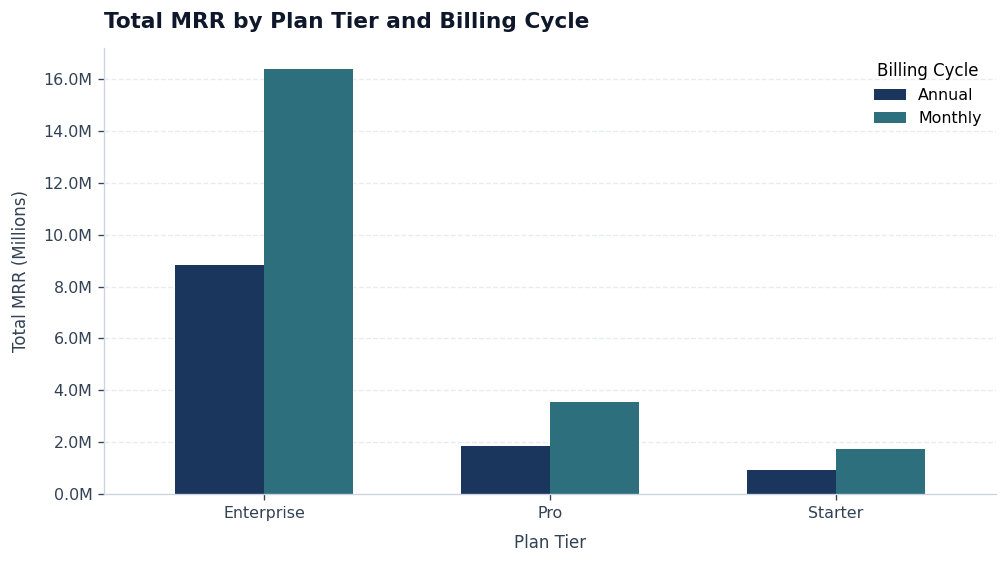

In [16]:
# Chart 1: Grouped Bar Chart - Total MRR by Plan Tier and Billing Cycle
fig, ax = plt.subplots(figsize=(8.5, 4.8))
pivot_mrr.plot(kind='bar', ax=ax, color=PALETTE_2, width=0.62)
style_consulting_ax(
    ax,
    title='Total MRR by Plan Tier and Billing Cycle',
    xlabel='Plan Tier',
    ylabel='Total MRR (Millions)',
    grid_axis='y',
)
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'{x / 1e6:.1f}M')
)
ax.legend(title='Billing Cycle', frameon=False, fontsize=9.5, title_fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

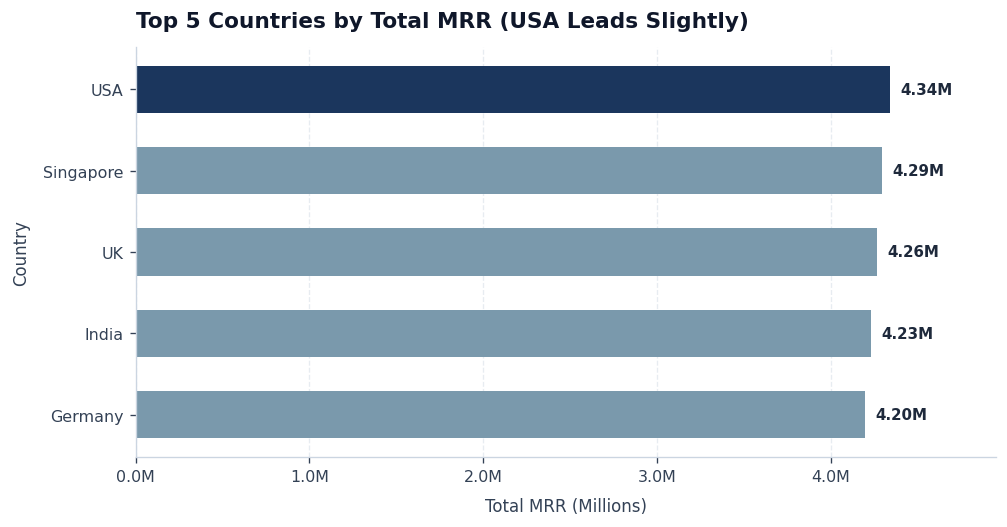

In [17]:

# Chart 2: Horizontal Bar Chart - Top 5 Countries by Total MRR
top5_countries_series = (
    df_clean.groupby('Country', observed=False)['Monthly_Recurring_Revenue']
    .sum()
    .sort_values(ascending=True)
    .tail(5)
)
bar_colors_c2 = [SLATE] * (len(top5_countries_series) - 1) + [NAVY]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.barh(
    top5_countries_series.index,
    top5_countries_series.values,
    color=bar_colors_c2,
    height=0.58,
)
style_consulting_ax(
    ax,
    title='Top 5 Countries by Total MRR (USA Leads Slightly)',
    xlabel='Total MRR (Millions)',
    ylabel='Country',
    grid_axis='x',
)
ax.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'{x / 1e6:.1f}M')
)
for bar in bars:
    val = bar.get_width()
    ax.text(
        val + 60000,
        bar.get_y() + bar.get_height() / 2,
        f'{val / 1e6:.2f}M',
        va='center',
        ha='left',
        fontsize=9,
        color='#1E293B',
        fontweight='bold',
    )
ax.set_xlim(0, top5_countries_series.max() * 1.14)
plt.tight_layout()
plt.show()


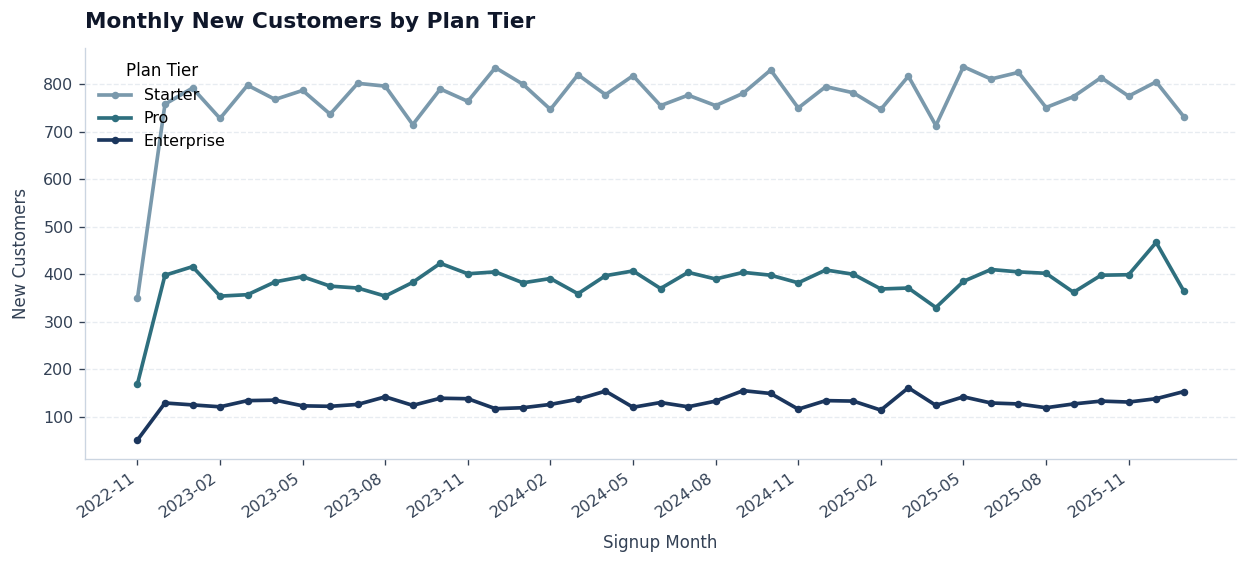

In [18]:
# Chart 3: Line Chart - Monthly New Customers by Plan Tier
monthly_plan = (
    df_clean.groupby(['Signup_Month', 'Plan_Tier'], observed=False)['Customer_ID']
    .count()
    .unstack(fill_value=0)
)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for col, color in zip(
    ['Starter', 'Pro', 'Enterprise'], [SLATE, TEAL, NAVY]
):
    if col in monthly_plan.columns:
        ax.plot(
            monthly_plan.index,
            monthly_plan[col],
            label=col,
            color=color,
            linewidth=2.2,
            marker='o',
            markersize=3.5,
        )
style_consulting_ax(
    ax,
    title='Monthly New Customers by Plan Tier',
    xlabel='Signup Month',
    ylabel='New Customers',
    grid_axis='y',
)
ax.legend(title='Plan Tier', frameon=False, fontsize=9.5, title_fontsize=10)
step = max(1, len(monthly_plan.index) // 10)
ax.set_xticks(range(0, len(monthly_plan.index), step))
ax.set_xticklabels(
    monthly_plan.index[::step], rotation=35, ha='right'
)
plt.tight_layout()
plt.show()

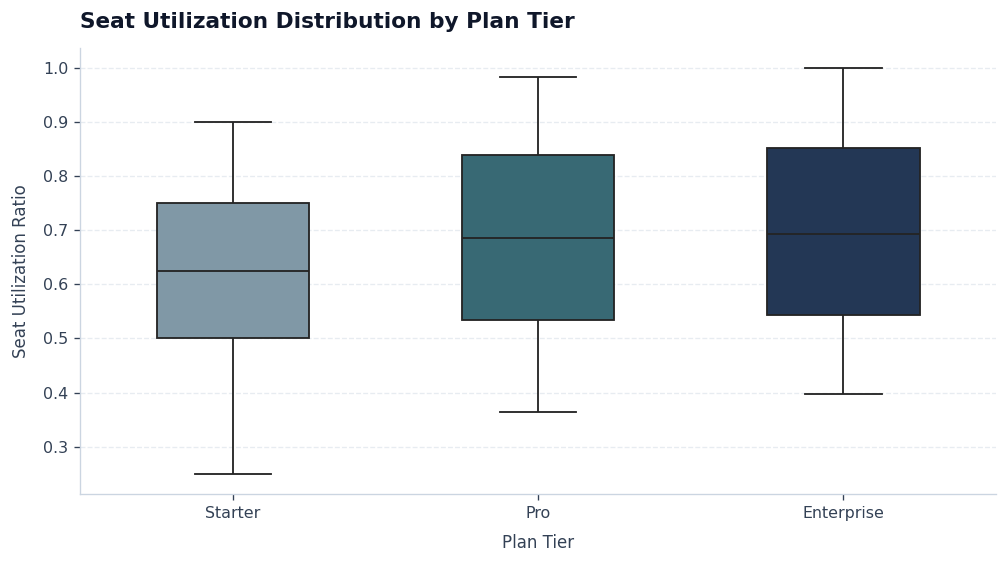

In [19]:
# Chart 4: Boxplot - Seat Utilization Distribution by Plan Tier
fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.boxplot(
    data=df_clean,
    x='Plan_Tier',
    y='Seat_Utilization',
    order=['Starter', 'Pro', 'Enterprise'],
    palette=PALETTE_3,
    width=0.5,
    linewidth=1.1,
    ax=ax,
)
style_consulting_ax(
    ax,
    title='Seat Utilization Distribution by Plan Tier',
    xlabel='Plan Tier',
    ylabel='Seat Utilization Ratio',
    grid_axis='y',
)
plt.tight_layout()
plt.show()

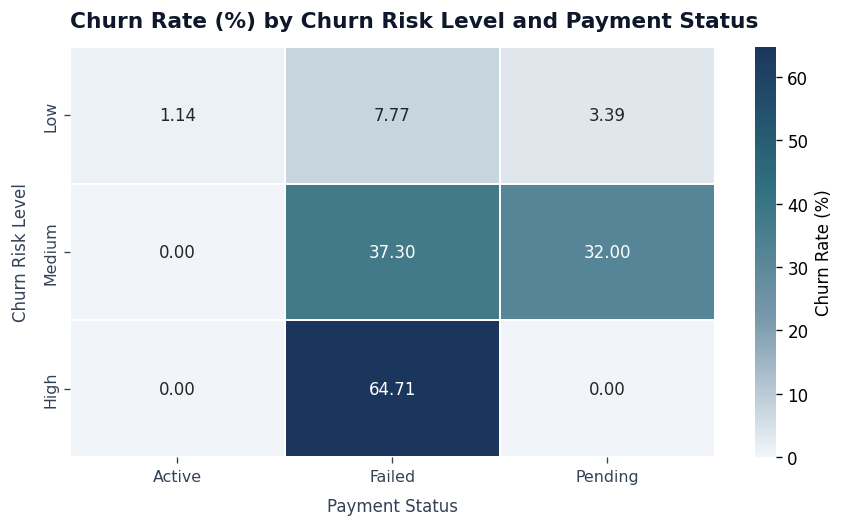

In [20]:
from matplotlib.colors import LinearSegmentedColormap

# Chart 5: Heatmap - Churn Rate (%) by Churn Risk Level and Payment Status
heat_churn = (
    pd.pivot_table(
        df_clean,
        values='Is_Churned',
        index='Churn_Risk_Level',
        columns='Payment_Status',
        aggfunc='mean',
        fill_value=0.0,
        observed=False,
    )
    * 100
).round(2)

# Single-palette sequential map aligned with the consulting navy/teal theme
unified_heatmap_cmap = LinearSegmentedColormap.from_list(
    'consulting_navy_teal',
    ['#F1F5F9', '#7A99AC', '#2E6F7E', '#1B365D'],
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(
    heat_churn,
    annot=True,
    fmt='.2f',
    cmap=unified_heatmap_cmap,
    linewidths=1.2,
    linecolor='#FFFFFF',
    cbar_kws={'label': 'Churn Rate (%)'},
    ax=ax,
)
style_consulting_ax(
    ax,
    title='Churn Rate (%) by Churn Risk Level and Payment Status',
    xlabel='Payment Status',
    ylabel='Churn Risk Level',
    grid_axis=None,
)
plt.tight_layout()
plt.show()

## 6. Executive Summary and Recommendations

### Executive Summary
Across **50,000 B2B SaaS customer accounts** and **33,267,908 in Total MRR**, overall customer churn is **1.83%** and total churned MRR is **396,040** (**1.19%** of total portfolio MRR). Revenue and retention patterns point to clear operational levers:
* **Monetization vs. Volume:** `Enterprise` drives the highest total MRR (approx. 16.39M `Monthly` and approx. 8.82M `Annual`) with low churn (1.01%–1.36%), while `Starter` accounts for the largest customer volume (30,008 accounts overall) and the highest churn rate (2.24%–2.30%). Smaller companies (`1-10` and `11-50`) also show higher churn (2.27%–2.31%) than mid-to-large segments (`201-500`, `501-1000`, `1000+`).
* **Leading Indicators of Churn:** Payment issues (`Failed` at 14.49% churn; `Pending` at 3.63%) and prolonged inactivity (`31-90 days` and `90+ days` at 100.00% churn) are strong signals of revenue loss. Similarly, `Churn_Risk_Level` aligns tightly with observed churn (1.49% in `Low`, 37.00% in `Medium`, and 64.71% in `High`), accompanied by higher 30-day support tickets and lower feature adoption.
* **Utilization & Growth Stability:** Seat utilization averages ~60.56%–69.68% across plans (with nearly a quarter of `Starter` users below 50% utilization), while monthly signups stay consistent after the initial `2022-11` ramp-up.

### Strategic Recommendations
1. **Automate Early Retention & Payment Recovery:** Trigger outreach before accounts pass 30 inactive days, run immediate retry/dunning workflows on `Failed` and `Pending` payments, and escalate `High` and `Medium` risk accounts (especially those with elevated support ticket volume) to Customer Success.
2. **Improve `Starter` Onboarding & Seat Right-Sizing:** Guide new and small-company users to core features early to reduce `Starter` churn, help low-utilization accounts (<50% seats) optimize seat counts, and target high-utilization (`90%+`) `Pro` and `Enterprise` accounts for expansion.
3. **Operationalize Churn & MRR Monitoring in BI:** Track `Churned_MRR`, `Seat_Utilization`, `Days_Since_Active`, and `Churn_Risk_Level` in an ongoing BI dashboard broken down by `Plan_Tier`, `Billing_Cycle`, and `Company_Size` to review retention impact continuously.